In [4]:
%pip install torch torchvision torchaudio nibabel scikit-learn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

MRI_IMAGE_DIR = r'C:\Users\Admin\Downloads\UCSF-PDGM-Complete'

# Loading dataset
df = pd.read_csv('UCSF-PDGM-metadata_v5.csv')
df['IDH_binary'] = df['IDH'].apply(lambda x: 0 if str(x).strip().lower() == 'wildtype' else 1)

# patient-level splitting
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['IDH_binary'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['IDH_binary'])

print(f"Total Cohort:     {len(df)} patients")
print(f"Train Set:       {len(train_df)} patients ({train_df['IDH_binary'].sum()} mutant)")
print(f"Validation Set: {len(val_df)} patients ({val_df['IDH_binary'].sum()} mutant)")
print(f"Test Set:        {len(test_df)} patients ({test_df['IDH_binary'].sum()} mutant)")

Total Cohort:     501 patients
Train Set:       350 patients (72 mutant)
Validation Set: 75 patients (15 mutant)
Test Set:        76 patients (16 mutant)


In [12]:
import torch
import torch.nn as nn
import numpy as np
import nibabel as nib
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, confusion_matrix

# MRI dataset Loading
class MRIDataset(Dataset):
    
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        raw_id = str(self.df.loc[idx, 'ID']).strip()
        label = float(self.df.loc[idx, 'IDH_binary'])
        
        clean_id = raw_id.split('_')[0]
        
        parts = clean_id.split('-')
        if parts[-1].isdigit():
            num_val = int(parts[-1])
            formatted_id = f"{'-'.join(parts[:-1])}-{num_val:04d}"
        else:
            formatted_id = clean_id

        folder_candidates = [
            formatted_id,              
            f"{formatted_id}_nifti",    
            clean_id,                   
            raw_id                    
        ]

        file_candidates = [
            f"{formatted_id}_T1c.nii.gz",
            f"{formatted_id}_T1CE.nii.gz",
            f"{clean_id}_T1c.nii.gz",
            f"{clean_id}_T1CE.nii.gz",
            f"{raw_id}_T1c.nii.gz",
            f"{raw_id}_T1CE.nii.gz"
        ]

        img_path = None
        for folder in folder_candidates:
            for file_name in file_candidates:
                candidate = os.path.join(self.image_dir, folder, file_name)
                if os.path.exists(candidate):
                    img_path = candidate
                    break
            if img_path:
                break

        if img_path is not None:
            nifti_img = nib.load(img_path)
            data = nifti_img.get_fdata()
            
            slice_idx = data.shape[2] // 2
            img_slice = data[:, :, slice_idx]
            
            if np.std(img_slice) > 0:
                img_slice = (img_slice - np.mean(img_slice)) / np.std(img_slice)
            else:
                img_slice = np.zeros_like(img_slice)
        else:
            raise FileNotFoundError(
                f"File missing for Patient ID '{raw_id}' (Clean ID: '{formatted_id}') in '{self.image_dir}'."
            )
            
        img_3ch = np.stack([img_slice]*3, axis=-1).astype(np.float32)
        img_tensor = torch.tensor(img_3ch).permute(2, 0, 1)

        if self.transform:
            img_tensor = self.transform(img_tensor)

        return img_tensor, torch.tensor(label, dtype=torch.float32)

# Data Transform and Loader
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
])

train_dataset = MRIDataset(train_df, MRI_IMAGE_DIR, transform=transform_pipeline)
val_dataset   = MRIDataset(val_df, MRI_IMAGE_DIR, transform=transform_pipeline)
test_dataset  = MRIDataset(test_df, MRI_IMAGE_DIR, transform=transform_pipeline)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=16, shuffle=False)


# Model setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running baseline training on: {device}")

baseline_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = baseline_model.fc.in_features
baseline_model.fc = nn.Linear(num_ftrs, 1)
baseline_model = baseline_model.to(device)

num_neg = (train_df['IDH_binary'] == 0).sum()
num_pos = (train_df['IDH_binary'] == 1).sum()
pos_weight_val = num_neg / num_pos
pos_weight = torch.tensor([pos_weight_val], dtype=torch.float32).to(device)
print(f"Training Class Ratio -> Neg: {num_neg}, Pos: {num_pos} | pos_weight: {pos_weight_val:.4f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-4)


# Training and Validation
NUM_EPOCHS = 10
best_val_auc = -1.0  
best_model_path = "best_baseline_resnet18.pt"

for epoch in range(NUM_EPOCHS):
    baseline_model.train()
    running_train_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = baseline_model(images).squeeze(-1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
        
    train_loss = running_train_loss / len(train_dataset)

    baseline_model.eval()
    running_val_loss = 0.0
    val_probs, val_targets = [], []
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            logits = baseline_model(images).squeeze(-1)
            loss = criterion(logits, labels)
            
            running_val_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(logits).cpu().numpy()
            
            val_probs.extend(probs)
            val_targets.extend(labels.cpu().numpy())
            
    val_loss = running_val_loss / len(val_dataset)
    val_auc = roc_auc_score(val_targets, val_probs)
    
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(baseline_model.state_dict(), best_model_path)
        saved_flag = "-> Best Model Saved!"
    else:
        saved_flag = ""

    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val ROC-AUC: {val_auc:.4f} {saved_flag}")


# Evaluation
if os.path.exists(best_model_path):
    print("\nLoading best model weights from validation for testing...")
    baseline_model.load_state_dict(torch.load(best_model_path, map_location=device))
else:
    raise RuntimeError("No validation checkpoint was saved. Test evaluation stopped.")

baseline_model.eval()

all_probs, all_targets = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = baseline_model(images).squeeze(-1)
        probs = torch.sigmoid(logits).cpu().numpy()
        
        all_probs.extend(probs)
        all_targets.extend(labels.numpy())

all_probs = np.array(all_probs)
all_targets = np.array(all_targets)
preds = (all_probs >= 0.20).astype(int)

print("\n Baseline Model Performance:")
print(f"Test ROC-AUC:    {roc_auc_score(all_targets, all_probs):.4f}")
print(f"Test F1-Score:   {f1_score(all_targets, preds):.4f}")
print(f"Test Precision: {precision_score(all_targets, preds, zero_division=0):.4f}")
print(f"Test Recall:     {recall_score(all_targets, preds, zero_division=0):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(all_targets, preds))

Running baseline training on: cpu
Training Class Ratio -> Neg: 278, Pos: 72 | pos_weight: 3.8611
Epoch [01/10] | Train Loss: 1.0464 | Val Loss: 0.9685 | Val ROC-AUC: 0.8133 -> Best Model Saved!
Epoch [02/10] | Train Loss: 0.3676 | Val Loss: 0.9951 | Val ROC-AUC: 0.8189 -> Best Model Saved!
Epoch [03/10] | Train Loss: 0.1284 | Val Loss: 0.9443 | Val ROC-AUC: 0.8100 
Epoch [04/10] | Train Loss: 0.0509 | Val Loss: 1.2290 | Val ROC-AUC: 0.7933 
Epoch [05/10] | Train Loss: 0.0460 | Val Loss: 0.9804 | Val ROC-AUC: 0.8322 -> Best Model Saved!
Epoch [06/10] | Train Loss: 0.0258 | Val Loss: 1.4533 | Val ROC-AUC: 0.8044 
Epoch [07/10] | Train Loss: 0.0206 | Val Loss: 1.2005 | Val ROC-AUC: 0.8167 
Epoch [08/10] | Train Loss: 0.0199 | Val Loss: 1.5234 | Val ROC-AUC: 0.7878 
Epoch [09/10] | Train Loss: 0.0142 | Val Loss: 1.5414 | Val ROC-AUC: 0.8078 
Epoch [10/10] | Train Loss: 0.0195 | Val Loss: 1.4032 | Val ROC-AUC: 0.7933 

Loading best model weights from validation for testing...

 Baseline Mod

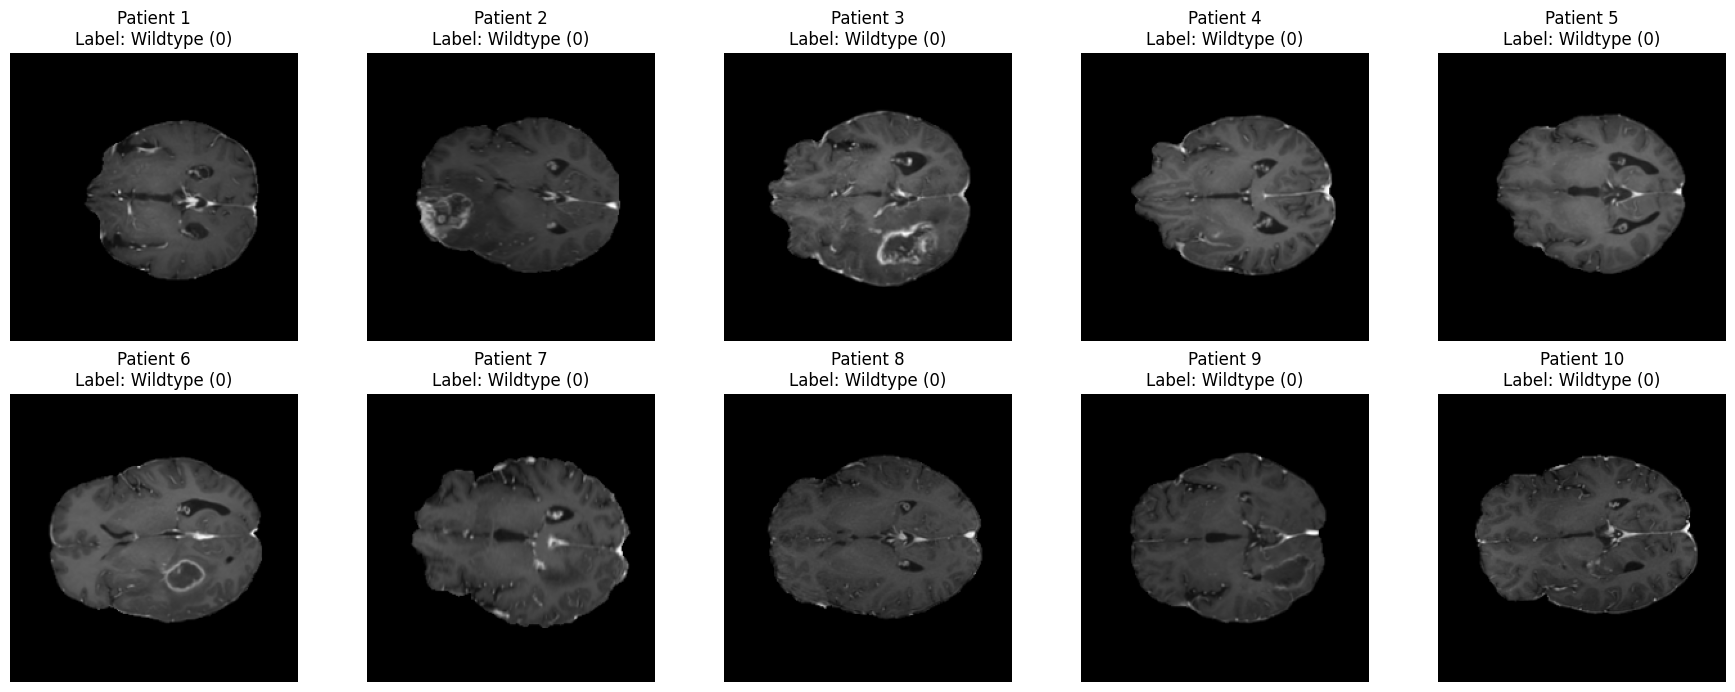


Successfully saved 10 PNG image files to:
C:\Users\Admin\Downloads\UCSF-PDGM-Complete\Saved_2D_Image_Slices


In [11]:
import matplotlib.pyplot as plt
output_dir = r'C:\Users\Admin\Downloads\UCSF-PDGM-Complete\Saved_2D_Image_Slices'
os.makedirs(output_dir, exist_ok=True)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

# Plotting and saving the first 10 patients image
for i in range(10):
  image_tensor, label = test_dataset[i]
  slice_img = image_tensor[0].cpu().numpy()

  label_str = 'Mutant (1)' if label.item() == 1.0 else 'Wildtype (0)'
  file_label_str = 'Mutant' if label.item() == 1.0 else 'Wildtype'

  axes.flat[i].imshow(slice_img, cmap='gray')
  axes.flat[i].set_title(f'Patient {i+1}\nLabel: {label_str}')
  axes.flat[i].axis('off')

  # Exporting
  filename = f'Patient_{i+1:02d}_{file_label_str}.png'
  filepath = os.path.join(output_dir, filename)
  plt.imsave(filepath, slice_img, cmap='gray')

plt.tight_layout()
plt.show()

# Saving
print(f'\nSuccessfully saved 10 PNG image files to:\n{output_dir}')